# Expolre the data

In [1]:
import pandas as pd
import numpy as np
import networkx as nx

In [2]:
mg1655_expression = pd.read_csv(
    "precise_mg1655_all/precise_mg1655-log_tpm_expression.csv"
)

mg1655_expression

,gene_id,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0001,-0.508210,1.780489,0.722802,1.476414,2.383642,4.112133,3.730746,-0.196990,-0.997967,...,-1.984772,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660
1,b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,1.125288,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
2,b0003,0.392437,-0.100001,0.091438,-0.916514,-0.981507,-0.336039,-0.183540,1.444999,1.716814,...,-0.915576,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829
3,b0004,-0.096891,-0.426017,-0.045651,-1.383575,-1.366994,-0.585717,-0.474251,1.103980,1.477590,...,-0.640566,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335
4,b0005,-0.181680,-1.168733,-0.470824,-2.116620,-2.018665,-1.132125,-1.144595,0.609102,0.043054,...,-0.601563,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4300,b4820,1.458344,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4301,b4821,-0.822529,1.806504,-2.174971,-2.034266,-3.664961,-6.407322,-6.407322,-0.252035,-2.402241,...,0.078410,1.066561,0.871170,1.255993,1.516656,-1.903401,-2.033700,-6.407322,-3.318284,-2.658700
4302,b4822,-0.922037,0.000000,3.155315,2.921023,1.534667,1.915924,2.034781,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.100396,1.608410,1.808631,2.662677
4303,b4823,1.640840,0.000000,2.046412,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [3]:
mg1655_network_interactions = pd.read_csv("mg1655_protein_physical_interaction.txt", sep=r"\s+")
mg1655_network_interactions

,protein1,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score
0,511145.b0002,511145.b0436,0,456,0,0,0,0,0,456
1,511145.b0002,511145.b0473,0,0,174,0,0,0,0,174
2,511145.b0002,511145.b1945,0,0,775,0,0,0,0,775
3,511145.b0002,511145.b2926,0,0,177,0,0,0,0,177
4,511145.b0002,511145.b3347,0,0,338,0,0,0,0,338
...,...,...,...,...,...,...,...,...,...,...
93703,511145.b4602,511145.b0432,0,0,0,900,0,0,0,900
93704,511145.b4602,511145.b0430,0,0,0,900,0,0,0,900
93705,511145.b4602,511145.b0429,0,0,0,900,0,0,0,900
93706,511145.b4602,511145.b4515,0,800,0,900,0,0,0,979


In [4]:
mg1655_network_interactions["gene1"] = (
    mg1655_network_interactions["protein1"]
    .str.replace("511145.", "", regex=False)
)

mg1655_network_interactions["gene2"] = (
    mg1655_network_interactions["protein2"]
    .str.replace("511145.", "", regex=False)
)
mg1655_network_interactions

,protein1,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,gene1,gene2
0,511145.b0002,511145.b0436,0,456,0,0,0,0,0,456,b0002,b0436
1,511145.b0002,511145.b0473,0,0,174,0,0,0,0,174,b0002,b0473
2,511145.b0002,511145.b1945,0,0,775,0,0,0,0,775,b0002,b1945
3,511145.b0002,511145.b2926,0,0,177,0,0,0,0,177,b0002,b2926
4,511145.b0002,511145.b3347,0,0,338,0,0,0,0,338,b0002,b3347
...,...,...,...,...,...,...,...,...,...,...,...,...
93703,511145.b4602,511145.b0432,0,0,0,900,0,0,0,900,b4602,b0432
93704,511145.b4602,511145.b0430,0,0,0,900,0,0,0,900,b4602,b0430
93705,511145.b4602,511145.b0429,0,0,0,900,0,0,0,900,b4602,b0429
93706,511145.b4602,511145.b4515,0,800,0,900,0,0,0,979,b4602,b4515


### PCA
##### sample-level PCA, samples x genes
1. rows = samples
2. cols = genes

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [6]:
# set gene_id as index
expr = mg1655_expression.set_index("gene_id")
expr

,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,pmg_wt_107,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
gene_id,,,,,,,,,,,,,,,,,,,,,
b0001,-0.508210,1.780489,0.722802,1.476414,2.383642,4.112133,3.730746,-0.196990,-0.997967,1.090242,...,-1.984772,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660
b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,1.125288,-0.955810,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
b0003,0.392437,-0.100001,0.091438,-0.916514,-0.981507,-0.336039,-0.183540,1.444999,1.716814,-0.803884,...,-0.915576,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829
b0004,-0.096891,-0.426017,-0.045651,-1.383575,-1.366994,-0.585717,-0.474251,1.103980,1.477590,-0.741174,...,-0.640566,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335
b0005,-0.181680,-1.168733,-0.470824,-2.116620,-2.018665,-1.132125,-1.144595,0.609102,0.043054,-0.298003,...,-0.601563,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
b4820,1.458344,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
b4821,-0.822529,1.806504,-2.174971,-2.034266,-3.664961,-6.407322,-6.407322,-0.252035,-2.402241,-2.379444,...,0.078410,1.066561,0.871170,1.255993,1.516656,-1.903401,-2.033700,-6.407322,-3.318284,-2.658700
b4822,-0.922037,0.000000,3.155315,2.921023,1.534667,1.915924,2.034781,0.000000,0.000000,1.339832,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.100396,1.608410,1.808631,2.662677


In [7]:
X = expr.T
X.shape

(586, 4305)

In [8]:
X

gene_id,b0001,b0002,b0003,b0004,b0005,b0006,b0007,b0008,b0009,b0010,...,b4815,b4816,b4817,b4818,b4819,b4820,b4821,b4822,b4823,b4824
pmg_wt_1,-0.508210,0.182318,0.392437,-0.096891,-0.181680,-0.173310,0.102564,-0.142828,-0.142569,-0.337247,...,-1.300123,-0.790408,-0.457671,-0.326880,1.288670,1.458344,-0.822529,-0.922037,1.640840,-2.927843
pmg_wt_10,1.780489,-0.197608,-0.100001,-0.426017,-1.168733,-0.655375,0.527317,-0.652939,-1.392046,-1.318235,...,0.000000,-0.720115,0.821900,4.002248,2.314676,0.000000,1.806504,0.000000,0.000000,0.000000
pmg_wt_100,0.722802,-0.822170,0.091438,-0.045651,-0.470824,-0.340454,2.796091,1.365931,1.201413,1.036406,...,0.000000,0.000000,1.577454,-3.130411,2.208604,0.000000,-2.174971,3.155315,2.046412,0.879156
pmg_wt_101,1.476414,-1.536439,-0.916514,-1.383575,-2.116620,-0.464066,1.000627,0.635379,1.163233,2.096654,...,0.000000,0.000000,2.091125,-3.531822,4.983363,0.000000,-2.034266,2.921023,0.000000,-0.252976
pmg_wt_102,2.383642,-1.543038,-0.981507,-1.366994,-2.018665,-0.310473,0.994919,0.603098,1.136169,2.362649,...,0.000000,0.000000,1.685503,-3.719146,5.254089,0.000000,-3.664961,1.534667,0.000000,-0.394900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
pmg_wt_95,1.347708,-0.117049,0.119124,0.012734,-0.906826,0.308993,1.993087,0.948028,1.183566,1.245678,...,0.000000,0.000000,1.427035,-1.432930,2.538430,0.000000,-1.903401,0.000000,0.000000,-1.981120
pmg_wt_96,1.841094,-0.147349,0.021417,-0.067448,-0.701478,0.015985,1.768211,1.036374,1.097356,0.848521,...,0.000000,0.000000,1.071235,-2.688116,3.631150,0.000000,-2.033700,2.100396,0.000000,-1.981120
pmg_wt_97,-0.552674,-1.088351,-0.765254,-0.590740,-1.423720,-0.275813,-0.399811,0.993569,0.977128,1.289848,...,0.000000,0.000000,0.255989,-6.964287,2.818412,0.000000,-6.407322,1.608410,0.000000,-1.981120
pmg_wt_98,-1.566595,-0.983296,-0.525073,-0.351376,-1.224787,-0.378874,0.061727,1.049810,1.603740,1.713409,...,0.000000,0.000000,0.137900,-3.732741,-0.036785,0.000000,-3.318284,1.808631,0.000000,-1.981120


In [9]:
#PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [10]:
# create dataframe
pca_df = pd.DataFrame(X_pca,columns=["PC1","PC2"], index=X.index)

#print explained variance
print(
    f"PC1 explained variance:"
    f"{pca.explained_variance_ratio_[0]*100:.2f}%"
)

print(
    f"PC2 explained variance:"
    f"{pca.explained_variance_ratio_[1]*100:.2f}%"
)

PC1 explained variance:31.26%
PC2 explained variance:9.11%


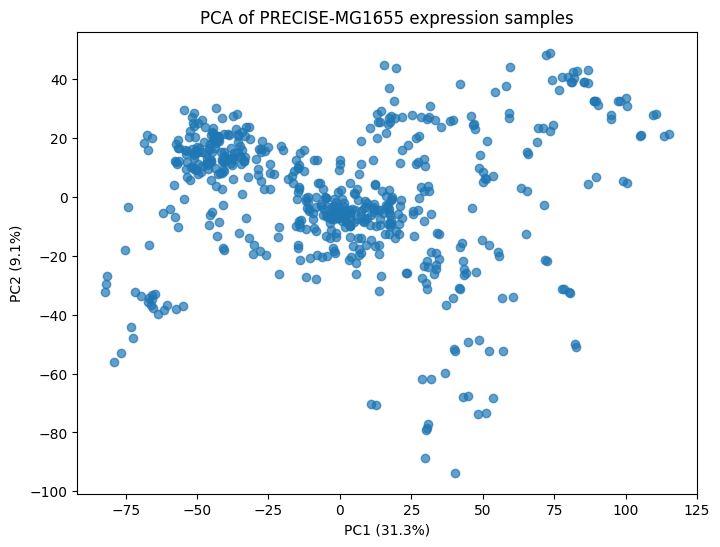

In [12]:
#plot
plt.figure(figsize=(8,6))
plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.7
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of PRECISE-MG1655 expression samples")
plt.show()

In [13]:
sample_metadata = pd.read_csv(
    "precise_mg1655_all/precise_mg1655-sample_table.csv"
)
sample_metadata.head()

,unique_identifier,project_name,condition,replicate_id,reference_condition_identifier,reference_strain,deleted_genes,mutated_genes,overexpressed_genes,perturbed_gene_ids,...,Trace Element Mixture,Run,SRX,n_replicates,passed_pct_reads_mapped,passed_number_replicates,passed_similar_replicates,Antibiotic for selection,enriched_condition,enriched_project
0,pmg_wt_1,pan_fur,WT,1,pmg_wt_445;pmg_wt_446,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[object Object],[object Object]
1,pmg_wt_10,in_house_2,stationary,2,pmg_wt_3;pmg_wt_4,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,pmg_wt_100,single_nutrient_perturbation,Uridine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pmg_wt_101,single_nutrient_perturbation,Glucose_L-Ornithine,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,pmg_wt_102,single_nutrient_perturbation,Glucose_L-Ornithine,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
pca_df

,PC1,PC2
pmg_wt_1,-3.423831,-6.718281
pmg_wt_10,30.935421,-23.882445
pmg_wt_100,31.665043,30.810782
pmg_wt_101,105.307106,21.025168
pmg_wt_102,104.915276,20.844228
...,...,...
pmg_wt_95,50.149616,8.498196
pmg_wt_96,48.771503,9.726594
pmg_wt_97,29.737362,10.547726
pmg_wt_98,29.535901,12.908368


In [16]:
pca_df = pca_df.reset_index()
pca_df = pca_df.rename(
    columns={"index":"unique_identifier"}
)

In [17]:
pca_df

,unique_identifier,PC1,PC2
0,pmg_wt_1,-3.423831,-6.718281
1,pmg_wt_10,30.935421,-23.882445
2,pmg_wt_100,31.665043,30.810782
3,pmg_wt_101,105.307106,21.025168
4,pmg_wt_102,104.915276,20.844228
...,...,...,...
581,pmg_wt_95,50.149616,8.498196
582,pmg_wt_96,48.771503,9.726594
583,pmg_wt_97,29.737362,10.547726
584,pmg_wt_98,29.535901,12.908368


In [18]:
#merge
pca_meta = pca_df.merge(
    sample_metadata,
    on="unique_identifier",
    how="left"
)
pca_meta

,unique_identifier,PC1,PC2,project_name,condition,replicate_id,reference_condition_identifier,reference_strain,deleted_genes,mutated_genes,...,Trace Element Mixture,Run,SRX,n_replicates,passed_pct_reads_mapped,passed_number_replicates,passed_similar_replicates,Antibiotic for selection,enriched_condition,enriched_project
0,pmg_wt_1,-3.423831,-6.718281,pan_fur,WT,1,pmg_wt_445;pmg_wt_446,MG1655,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[object Object],[object Object]
1,pmg_wt_10,30.935421,-23.882445,in_house_2,stationary,2,pmg_wt_3;pmg_wt_4,MG1655,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,pmg_wt_100,31.665043,30.810782,single_nutrient_perturbation,Uridine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pmg_wt_101,105.307106,21.025168,single_nutrient_perturbation,Glucose_L-Ornithine,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,pmg_wt_102,104.915276,20.844228,single_nutrient_perturbation,Glucose_L-Ornithine,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581,pmg_wt_95,50.149616,8.498196,single_nutrient_perturbation,D-Galactose_NH4Cl,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
582,pmg_wt_96,48.771503,9.726594,single_nutrient_perturbation,D-Galactose_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
583,pmg_wt_97,29.737362,10.547726,single_nutrient_perturbation,Cytidine_NH4Cl,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
584,pmg_wt_98,29.535901,12.908368,single_nutrient_perturbation,Cytidine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
pca_meta["condition"].nunique()
pca_meta["condition"].value_counts()


condition
wt_glc                         18
wt_ph5                          4
wt_lb                           4
wt_glc_24hr                     3
ebk_hnq2_biod                   3
                               ..
Supp_Cysteine_(2mM)             2
Supp_Cytosine_(10mM)            2
Supp_D-Saccharic acid_(2mM)     2
Supp_D-Galactose_(2mM)          2
Cytidine_NH4Cl                  2
Name: count, Length: 281, dtype: int64

/var/folders/c_/fyry7h1d259f7hcwm7lp11hw0000gn/T/ipykernel_49001/2908723934.py:27: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


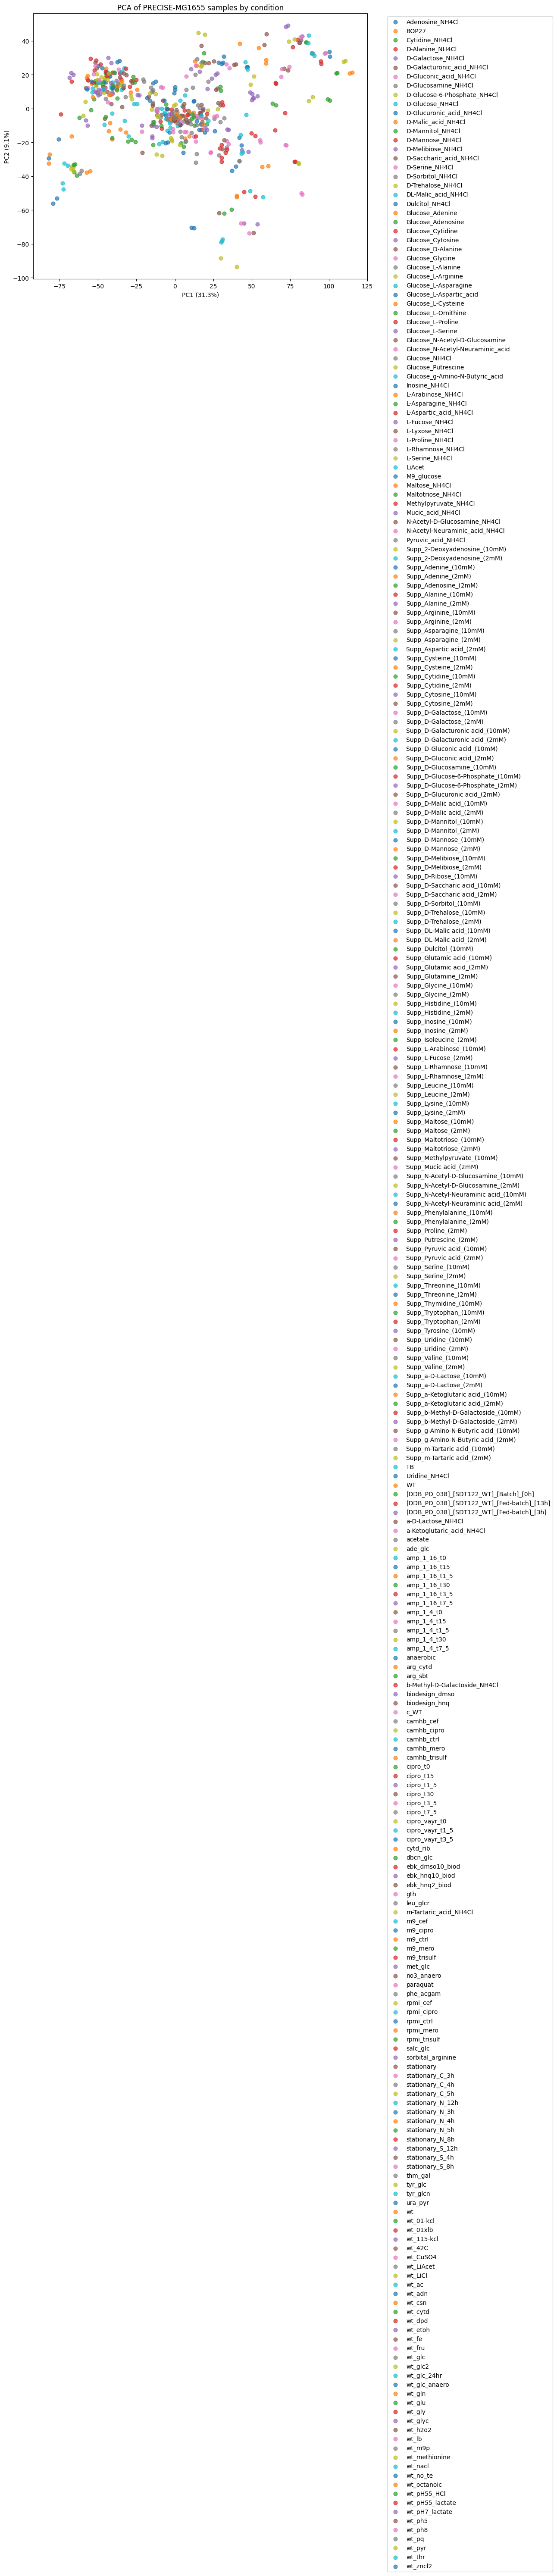

In [22]:
plt.figure(figsize=(10, 8))

for condition, group in pca_meta.groupby("condition"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=condition,
        alpha=0.7,
        s=40
    )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of PRECISE-MG1655 samples by condition")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [21]:
subset = pca_meta[
    pca_meta["project_name"] ==
    "single_nutrient_perturbation"
]
subset["condition"].value_counts()

condition
Uridine_NH4Cl                        2
Supp_Aspartic acid_(2mM)             2
Supp_Pyruvic acid_(2mM)              2
Supp_N-Acetyl-D-Glucosamine_(2mM)    2
Supp_D-Glucose-6-Phosphate_(2mM)     2
                                    ..
Supp_Tryptophan_(2mM)                2
Supp_Alanine_(2mM)                   2
Supp_Valine_(2mM)                    2
Supp_Alanine_(10mM)                  2
Cytidine_NH4Cl                       2
Name: count, Length: 161, dtype: int64

/var/folders/c_/fyry7h1d259f7hcwm7lp11hw0000gn/T/ipykernel_49001/314088972.py:28: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


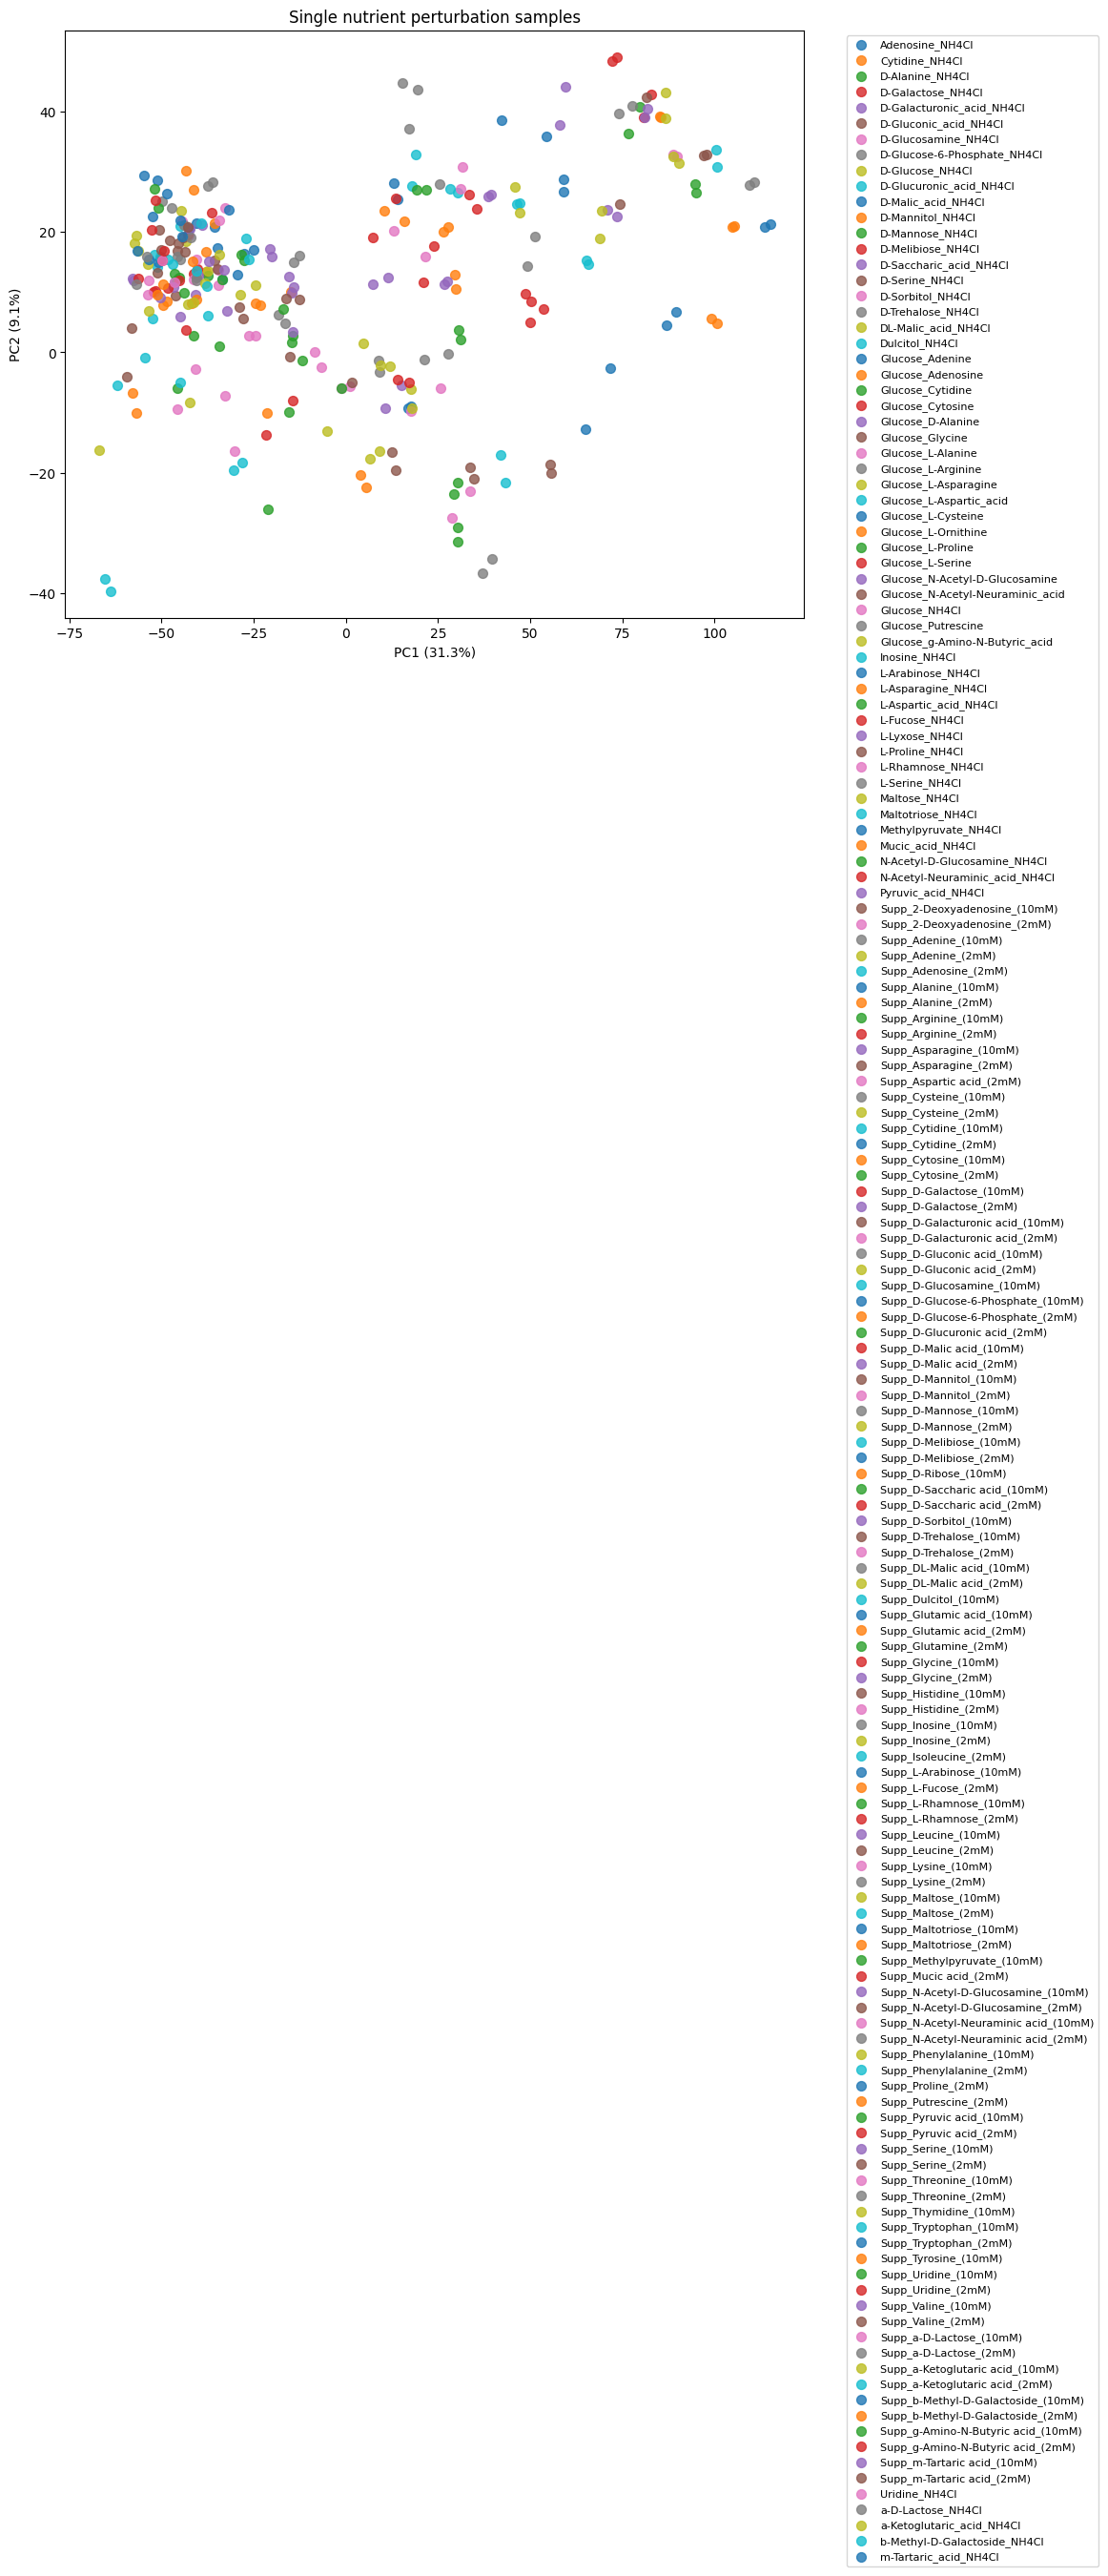

In [23]:
plt.figure(figsize=(10, 8))

for condition, group in subset.groupby("condition"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=condition,
        alpha=0.8,
        s=50
    )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("Single nutrient perturbation samples")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [26]:
nutrient_meta = sample_metadata[
    sample_metadata["project_name"] == "single_nutrient_perturbation"
].copy()

nutrient_ids = nutrient_meta["unique_identifier"]

In [27]:
X_nutrient = X.loc[
    X.index.intersection(nutrient_ids)
]

X_nutrient.shape

(322, 4305)

In [28]:
pca_nutrient = PCA(n_components=2)

pcs_nutrient = pca_nutrient.fit_transform(X_nutrient)

In [29]:
pca_nutrient_df = pd.DataFrame(
    pcs_nutrient,
    columns=["PC1", "PC2"],
    index=X_nutrient.index
).reset_index()

pca_nutrient_df = pca_nutrient_df.rename(
    columns={"index": "unique_identifier"}
)

In [30]:
pca_nutrient_meta = pca_nutrient_df.merge(
    nutrient_meta,
    on="unique_identifier",
    how="left"
)

In [32]:
print(
    f"PC1: {pca_nutrient.explained_variance_ratio_[0]*100:.1f}%"
)

print(
    f"PC2: {pca_nutrient.explained_variance_ratio_[1]*100:.1f}%"
)

PC1: 47.9%
PC2: 7.5%


In [37]:
pca_nutrient_meta[
    ["Carbon Source (g/L)", "Nitrogen Source (g/L)", "Base Media"]
].head(20)

,Carbon Source (g/L),Nitrogen Source (g/L),Base Media
0,Uridine(5),NH4Cl(1),M9
1,Glucose(5),L-Ornithine(1),M9
2,Glucose(5),L-Ornithine(1),M9
3,Glucose(5),Putrescine(1),M9
4,Glucose(5),Putrescine(1),M9
5,Glucose(5),N-Acetyl-Neuraminic_acid(1),M9
6,Glucose(5),N-Acetyl-Neuraminic_acid(1),M9
7,D-Trehalose(5),NH4Cl(1),M9
8,D-Trehalose(5),NH4Cl(1),M9
9,Glucose(5),g-Amino-N-Butyric_acid(1),M9


In [38]:
print(
    "Carbon sources:",
    pca_nutrient_meta["Carbon Source (g/L)"].nunique()
)

print(
    "Nitrogen sources:",
    pca_nutrient_meta["Nitrogen Source (g/L)"].nunique()
)

print(
    "Base media:",
    pca_nutrient_meta["Base Media"].nunique()
)

Carbon sources: 42
Nitrogen sources: 19
Base media: 1


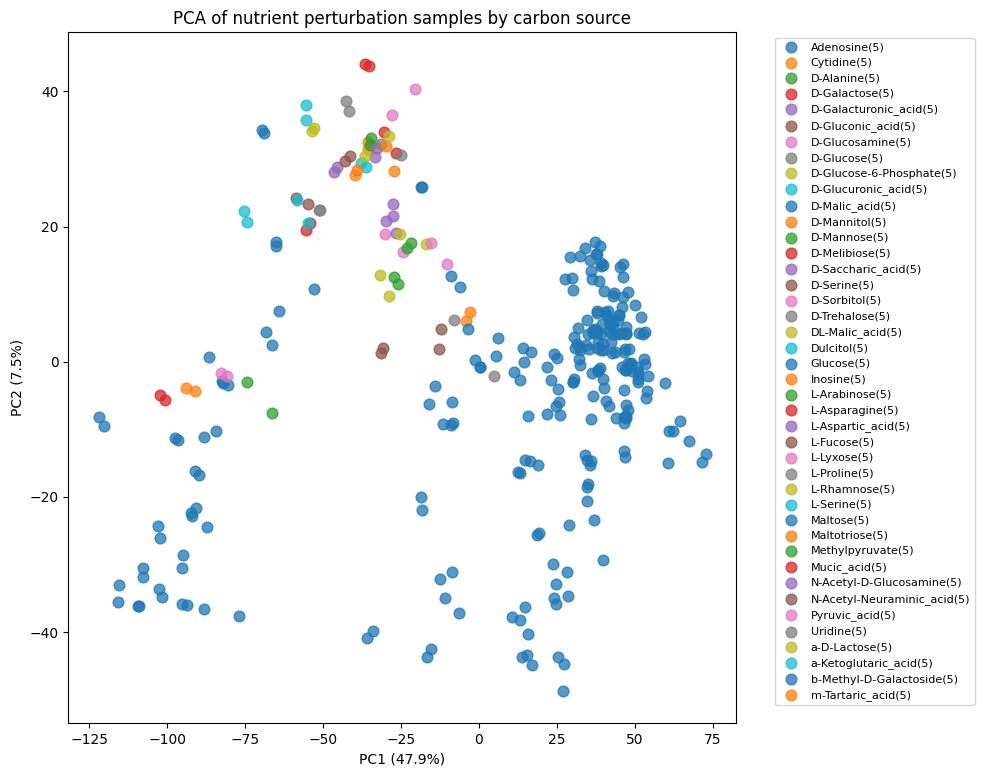

In [39]:
plt.figure(figsize=(10, 8))

for carbon, group in pca_nutrient_meta.groupby("Carbon Source (g/L)"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=carbon,
        s=60,
        alpha=0.75
    )

plt.xlabel(
    f"PC1 ({pca_nutrient.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca_nutrient.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of nutrient perturbation samples by carbon source")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

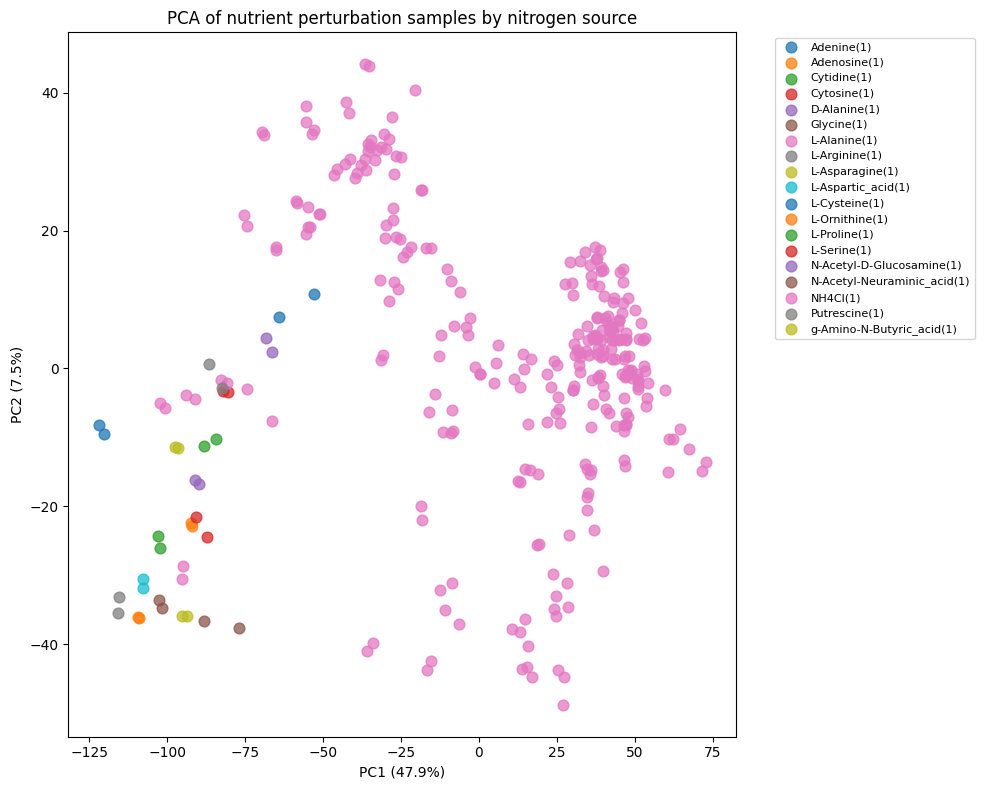

In [40]:
plt.figure(figsize=(10, 8))

for nitrogen, group in pca_nutrient_meta.groupby("Nitrogen Source (g/L)"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=nitrogen,
        s=60,
        alpha=0.75
    )

plt.xlabel(
    f"PC1 ({pca_nutrient.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca_nutrient.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of nutrient perturbation samples by nitrogen source")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [41]:
#Carbon-source experiment
carbon_meta = nutrient_meta[
    nutrient_meta["Nitrogen Source (g/L)"] == "NH4Cl(1)"
].copy()

In [43]:
carbon_meta["Carbon Source (g/L)"].value_counts()

Carbon Source (g/L)
Glucose(5)                     204
Uridine(5)                       2
L-Aspartic_acid(5)               2
D-Malic_acid(5)                  2
L-Lyxose(5)                      2
Pyruvic_acid(5)                  2
D-Galacturonic_acid(5)           2
N-Acetyl-Neuraminic_acid(5)      2
b-Methyl-D-Galactoside(5)        2
D-Glucosamine(5)                 2
D-Glucose(5)                     2
L-Proline(5)                     2
Methylpyruvate(5)                2
D-Alanine(5)                     2
L-Serine(5)                      2
L-Asparagine(5)                  2
D-Serine(5)                      2
Adenosine(5)                     2
Inosine(5)                       2
D-Galactose(5)                   2
D-Saccharic_acid(5)              2
Mucic_acid(5)                    2
D-Trehalose(5)                   2
Maltotriose(5)                   2
D-Mannose(5)                     2
Dulcitol(5)                      2
D-Sorbitol(5)                    2
L-Arabinose(5)                   2


In [44]:
carbon_ids = carbon_meta["unique_identifier"]

X_carbon = X.loc[
    X.index.intersection(carbon_ids)
]

In [45]:
X_carbon.shape

(286, 4305)

In [46]:
pca_carbon = PCA(n_components=2)

pcs_carbon = pca_carbon.fit_transform(X_carbon)

In [47]:
pca_carbon_df = pd.DataFrame(
    pcs_carbon,
    columns=["PC1", "PC2"],
    index=X_carbon.index
).reset_index()

pca_carbon_df = pca_carbon_df.rename(
    columns={"index": "unique_identifier"}
)

In [48]:
pca_carbon_meta = pca_carbon_df.merge(
    carbon_meta,
    on="unique_identifier",
    how="left"
)

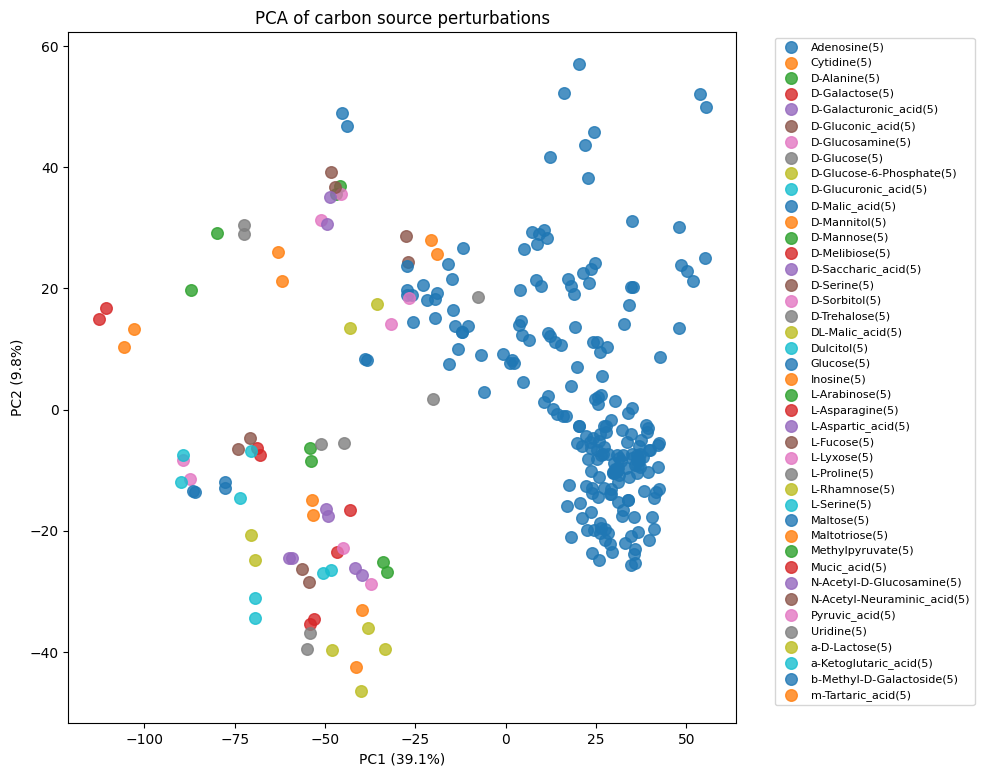

In [49]:
plt.figure(figsize=(10, 8))

for carbon, group in pca_carbon_meta.groupby("Carbon Source (g/L)"):

    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=carbon,
        s=70,
        alpha=0.8
    )

plt.xlabel(
    f"PC1 ({pca_carbon.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca_carbon.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of carbon source perturbations")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [50]:
nitrogen_meta = nutrient_meta[
    nutrient_meta["Carbon Source (g/L)"] == "Glucose(5)"
].copy()

In [51]:
nitrogen_meta[
    ["unique_identifier",
     "Carbon Source (g/L)",
     "Nitrogen Source (g/L)",
     "condition"]
].head(20)

,unique_identifier,Carbon Source (g/L),Nitrogen Source (g/L),condition
3,pmg_wt_101,Glucose(5),L-Ornithine(1),Glucose_L-Ornithine
4,pmg_wt_102,Glucose(5),L-Ornithine(1),Glucose_L-Ornithine
5,pmg_wt_103,Glucose(5),Putrescine(1),Glucose_Putrescine
6,pmg_wt_104,Glucose(5),Putrescine(1),Glucose_Putrescine
7,pmg_wt_105,Glucose(5),N-Acetyl-Neuraminic_acid(1),Glucose_N-Acetyl-Neuraminic_acid
8,pmg_wt_106,Glucose(5),N-Acetyl-Neuraminic_acid(1),Glucose_N-Acetyl-Neuraminic_acid
11,pmg_wt_109,Glucose(5),g-Amino-N-Butyric_acid(1),Glucose_g-Amino-N-Butyric_acid
13,pmg_wt_110,Glucose(5),g-Amino-N-Butyric_acid(1),Glucose_g-Amino-N-Butyric_acid
14,pmg_wt_111,Glucose(5),L-Alanine(1),Glucose_L-Alanine
15,pmg_wt_112,Glucose(5),L-Alanine(1),Glucose_L-Alanine


In [52]:
nitrogen_meta["Nitrogen Source (g/L)"].value_counts()

Nitrogen Source (g/L)
NH4Cl(1)                       204
L-Proline(1)                     2
N-Acetyl-D-Glucosamine(1)        2
Cytosine(1)                      2
Cytidine(1)                      2
Adenosine(1)                     2
Adenine(1)                       2
D-Alanine(1)                     2
L-Serine(1)                      2
L-Ornithine(1)                   2
Putrescine(1)                    2
L-Cysteine(1)                    2
L-Aspartic_acid(1)               2
L-Asparagine(1)                  2
L-Arginine(1)                    2
L-Alanine(1)                     2
g-Amino-N-Butyric_acid(1)        2
N-Acetyl-Neuraminic_acid(1)      2
Glycine(1)                       2
Name: count, dtype: int64

In [53]:
nitrogen_ids = nitrogen_meta["unique_identifier"]

X_nitrogen = X.loc[
    X.index.intersection(nitrogen_ids)
]

In [54]:
pca_nitrogen = PCA(n_components=2)

pcs_nitrogen = pca_nitrogen.fit_transform(X_nitrogen)

In [55]:
pca_nitrogen_df = pd.DataFrame(
    pcs_nitrogen,
    columns=["PC1", "PC2"],
    index=X_nitrogen.index
).reset_index()

pca_nitrogen_df = pca_nitrogen_df.rename(
    columns={"index": "unique_identifier"}
)

In [56]:
pca_nitrogen_meta = pca_nitrogen_df.merge(
    nitrogen_meta,
    on="unique_identifier",
    how="left"
)

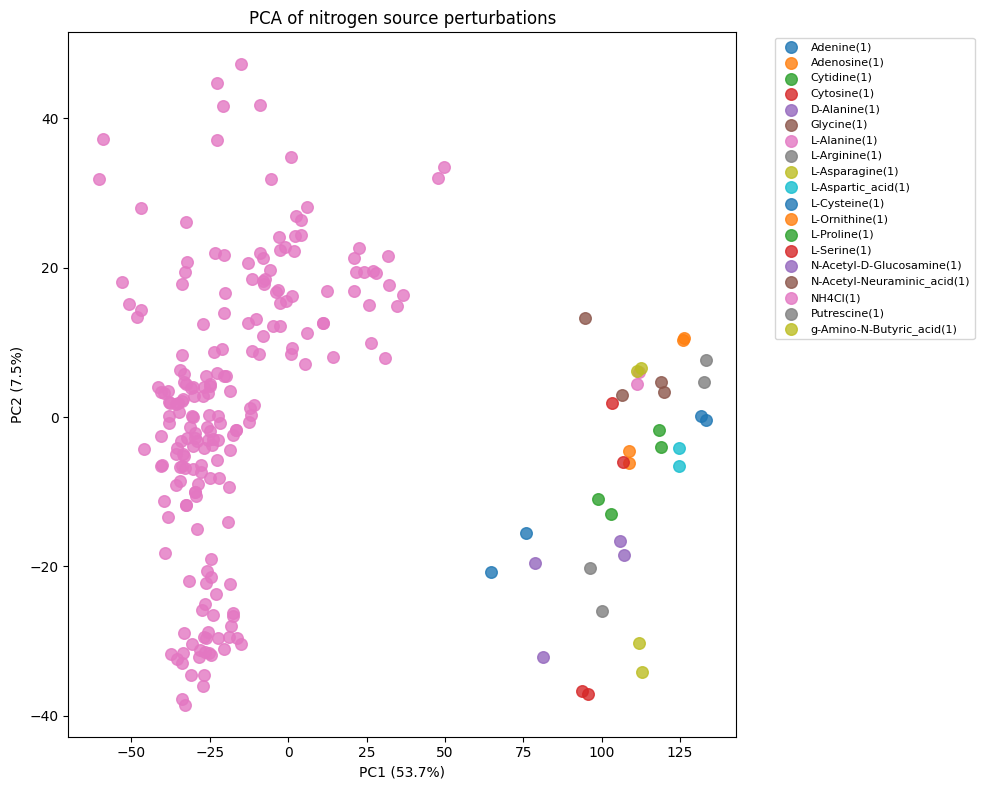

In [57]:
plt.figure(figsize=(10, 8))

for nitrogen, group in pca_nitrogen_meta.groupby("Nitrogen Source (g/L)"):

    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=nitrogen,
        s=70,
        alpha=0.8
    )

plt.xlabel(
    f"PC1 ({pca_nitrogen.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca_nitrogen.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of nitrogen source perturbations")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [58]:
nutrient_meta[
    nutrient_meta["condition"].str.startswith("Supp_", na=False)
]["condition"].head(20)

53                  Supp_Histidine_(2mM)
54                  Supp_Histidine_(2mM)
55           Supp_D-Gluconic acid_(10mM)
57           Supp_D-Gluconic acid_(10mM)
58                Supp_D-Mannitol_(10mM)
59                Supp_D-Mannitol_(10mM)
60                  Supp_D-Ribose_(10mM)
61                  Supp_D-Ribose_(10mM)
62                   Supp_Maltose_(10mM)
63                   Supp_Maltose_(10mM)
64               Supp_D-Melibiose_(10mM)
65               Supp_D-Melibiose_(10mM)
66              Supp_Pyruvic acid_(10mM)
68              Supp_Pyruvic acid_(10mM)
69             Supp_D-Glucosamine_(10mM)
70             Supp_D-Glucosamine_(10mM)
71               Supp_L-Arabinose_(10mM)
72               Supp_L-Arabinose_(10mM)
73    Supp_N-Acetyl-D-Glucosamine_(10mM)
74    Supp_N-Acetyl-D-Glucosamine_(10mM)
Name: condition, dtype: object

In [59]:
carbon_meta = nutrient_meta[
    (nutrient_meta["Nitrogen Source (g/L)"] == "NH4Cl(1)") &
    (~nutrient_meta["condition"].str.startswith("Supp_", na=False))
].copy()

In [60]:
carbon_meta[
    ["condition", "Carbon Source (g/L)", "Nitrogen Source (g/L)"]
].sort_values("condition")

,condition,Carbon Source (g/L),Nitrogen Source (g/L)
578,Adenosine_NH4Cl,Adenosine(5),NH4Cl(1)
577,Adenosine_NH4Cl,Adenosine(5),NH4Cl(1)
584,Cytidine_NH4Cl,Cytidine(5),NH4Cl(1)
583,Cytidine_NH4Cl,Cytidine(5),NH4Cl(1)
569,D-Alanine_NH4Cl,D-Alanine(5),NH4Cl(1)
...,...,...,...
433,a-Ketoglutaric_acid_NH4Cl,a-Ketoglutaric_acid(5),NH4Cl(1)
557,b-Methyl-D-Galactoside_NH4Cl,b-Methyl-D-Galactoside(5),NH4Cl(1)
558,b-Methyl-D-Galactoside_NH4Cl,b-Methyl-D-Galactoside(5),NH4Cl(1)
489,m-Tartaric_acid_NH4Cl,m-Tartaric_acid(5),NH4Cl(1)


In [61]:
carbon_meta["condition"].value_counts()

condition
Uridine_NH4Cl                     2
D-Glucose_NH4Cl                   2
D-Saccharic_acid_NH4Cl            2
D-Malic_acid_NH4Cl                2
L-Lyxose_NH4Cl                    2
Pyruvic_acid_NH4Cl                2
D-Galacturonic_acid_NH4Cl         2
N-Acetyl-Neuraminic_acid_NH4Cl    2
b-Methyl-D-Galactoside_NH4Cl      2
D-Glucosamine_NH4Cl               2
L-Aspartic_acid_NH4Cl             2
D-Trehalose_NH4Cl                 2
L-Proline_NH4Cl                   2
D-Alanine_NH4Cl                   2
L-Serine_NH4Cl                    2
L-Asparagine_NH4Cl                2
D-Serine_NH4Cl                    2
Adenosine_NH4Cl                   2
Inosine_NH4Cl                     2
D-Galactose_NH4Cl                 2
Methylpyruvate_NH4Cl              2
Mucic_acid_NH4Cl                  2
Maltotriose_NH4Cl                 2
m-Tartaric_acid_NH4Cl             2
D-Mannose_NH4Cl                   2
Dulcitol_NH4Cl                    2
D-Sorbitol_NH4Cl                  2
Glucose_NH4Cl     

In [62]:
nitrogen_meta = nutrient_meta[
    (nutrient_meta["Carbon Source (g/L)"] == "Glucose(5)") &
    (~nutrient_meta["condition"].str.startswith("Supp_", na=False))
].copy()

In [63]:
nitrogen_meta[
    ["condition", "Carbon Source (g/L)", "Nitrogen Source (g/L)"]
].sort_values("condition")

,condition,Carbon Source (g/L),Nitrogen Source (g/L)
37,Glucose_Adenine,Glucose(5),Adenine(1)
36,Glucose_Adenine,Glucose(5),Adenine(1)
39,Glucose_Adenosine,Glucose(5),Adenosine(1)
38,Glucose_Adenosine,Glucose(5),Adenosine(1)
41,Glucose_Cytidine,Glucose(5),Cytidine(1)
40,Glucose_Cytidine,Glucose(5),Cytidine(1)
43,Glucose_Cytosine,Glucose(5),Cytosine(1)
42,Glucose_Cytosine,Glucose(5),Cytosine(1)
33,Glucose_D-Alanine,Glucose(5),D-Alanine(1)
35,Glucose_D-Alanine,Glucose(5),D-Alanine(1)


In [64]:
carbon_ids = carbon_meta["unique_identifier"]

X_carbon = X.loc[X.index.intersection(carbon_ids)]

pca_carbon = PCA(n_components=2)
pcs_carbon = pca_carbon.fit_transform(X_carbon)

pca_carbon_df = pd.DataFrame(
    pcs_carbon,
    columns=["PC1", "PC2"],
    index=X_carbon.index
).reset_index()

pca_carbon_df = pca_carbon_df.rename(
    columns={"index": "unique_identifier"}
)

pca_carbon_meta = pca_carbon_df.merge(
    carbon_meta,
    on="unique_identifier",
    how="left"
)

In [65]:
nitrogen_ids = nitrogen_meta["unique_identifier"]

X_nitrogen = X.loc[X.index.intersection(nitrogen_ids)]

pca_nitrogen = PCA(n_components=2)
pcs_nitrogen = pca_nitrogen.fit_transform(X_nitrogen)

pca_nitrogen_df = pd.DataFrame(
    pcs_nitrogen,
    columns=["PC1", "PC2"],
    index=X_nitrogen.index
).reset_index()

pca_nitrogen_df = pca_nitrogen_df.rename(
    columns={"index": "unique_identifier"}
)

pca_nitrogen_meta = pca_nitrogen_df.merge(
    nitrogen_meta,
    on="unique_identifier",
    how="left"
)

In [66]:
print("Carbon samples:", len(pca_carbon_meta))
print("Carbon conditions:", pca_carbon_meta["condition"].nunique())

print("Nitrogen samples:", len(pca_nitrogen_meta))
print("Nitrogen conditions:", pca_nitrogen_meta["condition"].nunique())

Carbon samples: 84
Carbon conditions: 42
Nitrogen samples: 38
Nitrogen conditions: 19


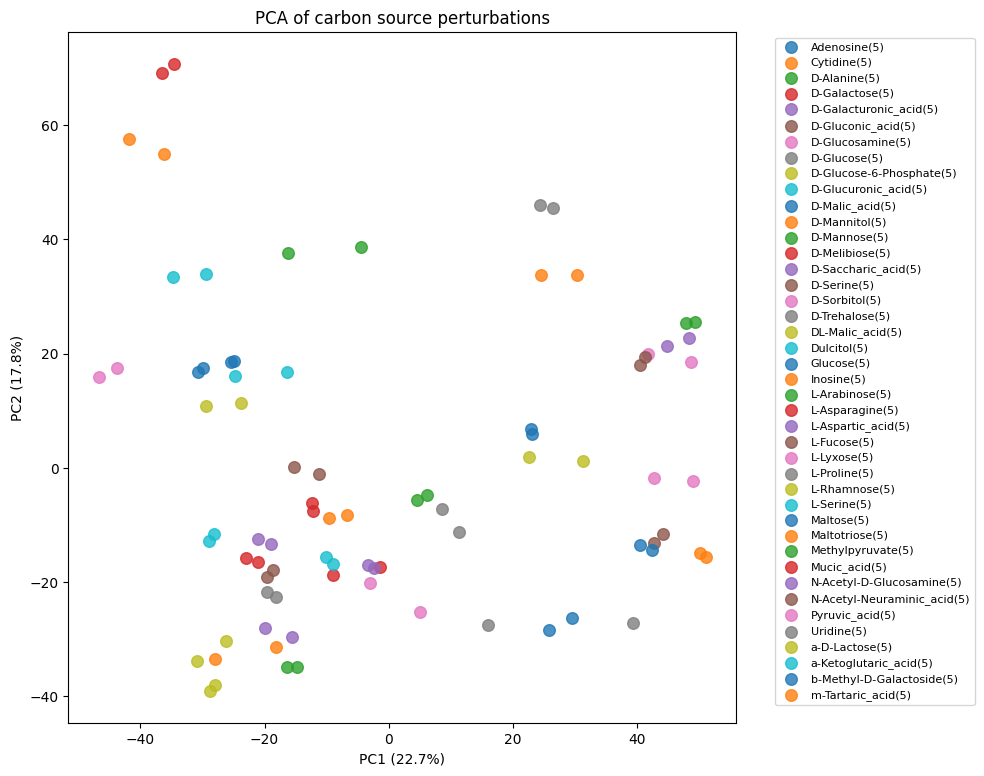

In [68]:
plt.figure(figsize=(10, 8))

for carbon, group in pca_carbon_meta.groupby("Carbon Source (g/L)"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=carbon,
        s=70,
        alpha=0.8
    )

plt.xlabel(
    f"PC1 ({pca_carbon.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca_carbon.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of carbon source perturbations")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

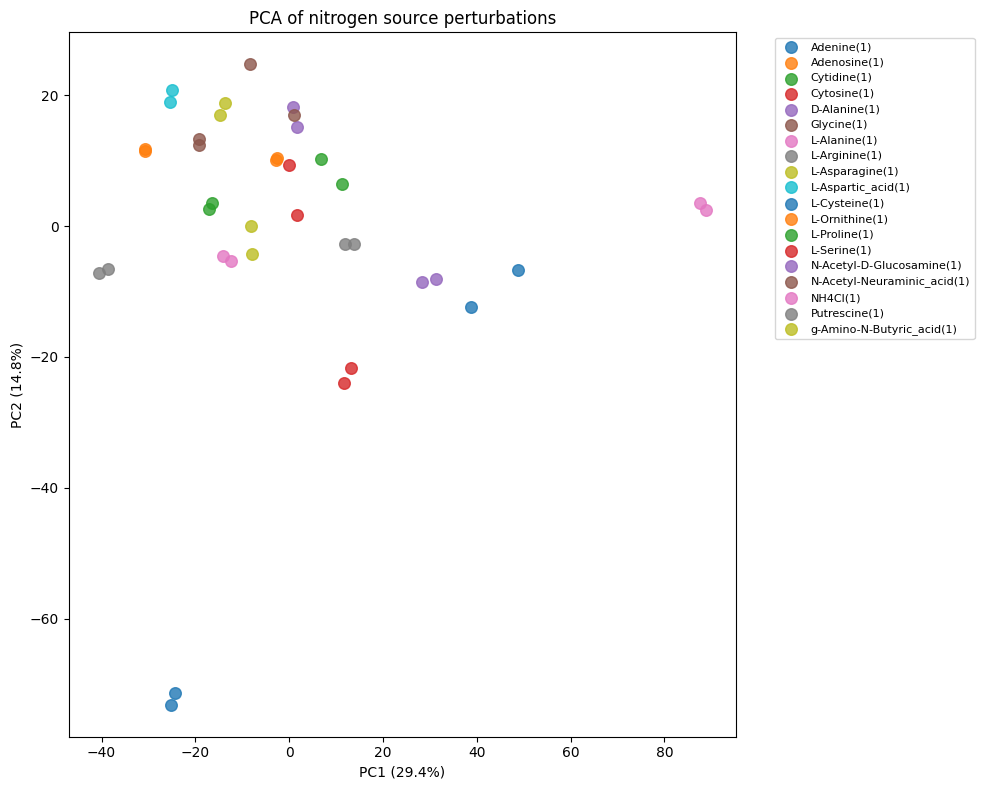

In [69]:
plt.figure(figsize=(10, 8))

for nitrogen, group in pca_nitrogen_meta.groupby("Nitrogen Source (g/L)"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=nitrogen,
        s=70,
        alpha=0.8
    )

plt.xlabel(
    f"PC1 ({pca_nitrogen.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca_nitrogen.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of nitrogen source perturbations")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

#### degree vs magnitude

In [94]:
#carbon
carbon_sample_info = pca_carbon_meta[
    ["unique_identifier", "Carbon Source (g/L)"]
].copy()

carbon_expr = X_carbon.copy()

carbon_expr["Carbon Source"] = (
    carbon_sample_info
    .set_index("unique_identifier")
    .loc[carbon_expr.index, "Carbon Source (g/L)"]
)

carbon_condition_mean = carbon_expr.groupby(
    "Carbon Source"
).mean()

carbon_magnitude = carbon_condition_mean.std(axis=0)

In [95]:
#nitrogen
#nitrogen plasticity = SD (expression across nitrogen environments)
nitrogen_sample_info = pca_nitrogen_meta[
    ["unique_identifier", "Nitrogen Source (g/L)"]
].copy()

nitrogen_expr = X_nitrogen.copy()

nitrogen_expr["Nitrogen Source"] = (
    nitrogen_sample_info
    .set_index("unique_identifier")
    .loc[nitrogen_expr.index, "Nitrogen Source (g/L)"]
)

nitrogen_condition_mean = nitrogen_expr.groupby(
    "Nitrogen Source"
).mean()

nitrogen_magnitude = nitrogen_condition_mean.std(axis=0)

In [96]:
#gene response table 
gene_response = pd.DataFrame({
    "gene_id": X.columns,
    "carbon_magnitude": carbon_magnitude.reindex(X.columns).values,
    "nitrogen_magnitude": nitrogen_magnitude.reindex(X.columns).values
})

In [97]:
gene_response["overall_magnitude"] = (
    gene_response[
        ["carbon_magnitude", "nitrogen_magnitude"]
    ].mean(axis=1)
)

In [98]:
gene_response

,gene_id,carbon_magnitude,nitrogen_magnitude,overall_magnitude
0,b0001,1.402353,1.483518,1.442936
1,b0002,0.790684,0.863685,0.827185
2,b0003,0.803711,0.754099,0.778905
3,b0004,0.810552,0.763206,0.786879
4,b0005,1.210592,0.749753,0.980172
...,...,...,...,...
4300,b4820,0.279969,0.502958,0.391463
4301,b4821,2.334664,1.648983,1.991824
4302,b4822,0.858672,0.996468,0.927570
4303,b4823,0.339778,0.299211,0.319494


### degree

In [99]:
G = nx.from_pandas_edgelist(
    mg1655_network_interactions,
    source="gene1",
    target="gene2"
)

In [100]:
degree = dict(G.degree())

In [101]:
gene_response["degree"] = (
    gene_response["gene_id"]
    .map(degree)
    .fillna(0)
)

In [102]:
gene_response

,gene_id,carbon_magnitude,nitrogen_magnitude,overall_magnitude,degree
0,b0001,1.402353,1.483518,1.442936,0.0
1,b0002,0.790684,0.863685,0.827185,11.0
2,b0003,0.803711,0.754099,0.778905,0.0
3,b0004,0.810552,0.763206,0.786879,11.0
4,b0005,1.210592,0.749753,0.980172,0.0
...,...,...,...,...,...
4300,b4820,0.279969,0.502958,0.391463,0.0
4301,b4821,2.334664,1.648983,1.991824,0.0
4302,b4822,0.858672,0.996468,0.927570,0.0
4303,b4823,0.339778,0.299211,0.319494,0.0


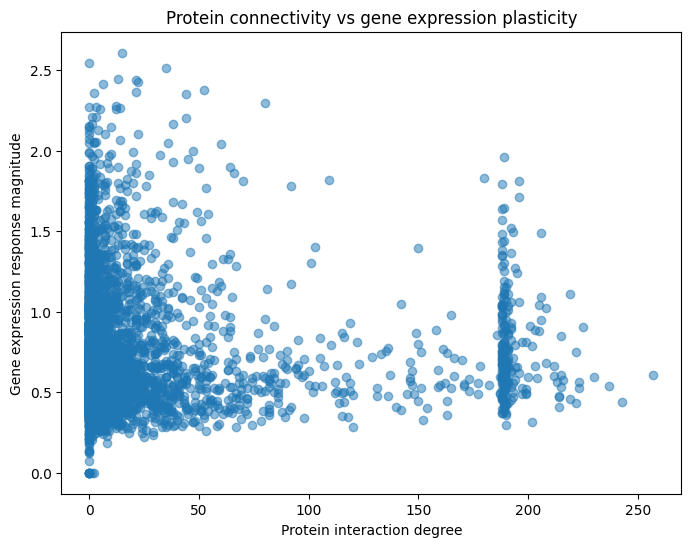

In [103]:
plt.figure(figsize=(8, 6))

plt.scatter(
    gene_response["degree"],
    gene_response["overall_magnitude"],
    alpha=0.5
)

plt.xlabel("Protein interaction degree")
plt.ylabel("Gene expression response magnitude")
plt.title("Protein connectivity vs gene expression plasticity")

plt.show()

In [104]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    gene_response["degree"],
    gene_response["overall_magnitude"]
)

print("Spearman rho:", rho)
print("p-value:", p)

Spearman rho: -0.05964710100806797
p-value: 9.005057427930597e-05


In [105]:
rho_c, p_c = spearmanr(
    gene_response["degree"],
    gene_response["carbon_magnitude"]
)

rho_n, p_n = spearmanr(
    gene_response["degree"],
    gene_response["nitrogen_magnitude"]
)

print("Carbon:")
print("rho =", rho_c)
print("p =", p_c)

print("Nitrogen:")
print("rho =", rho_n)
print("p =", p_n)

Carbon:
rho = -0.035077669956424355
p = 0.02135923757527995
Nitrogen:
rho = -0.07578525946514333
p = 6.418617202828943e-07


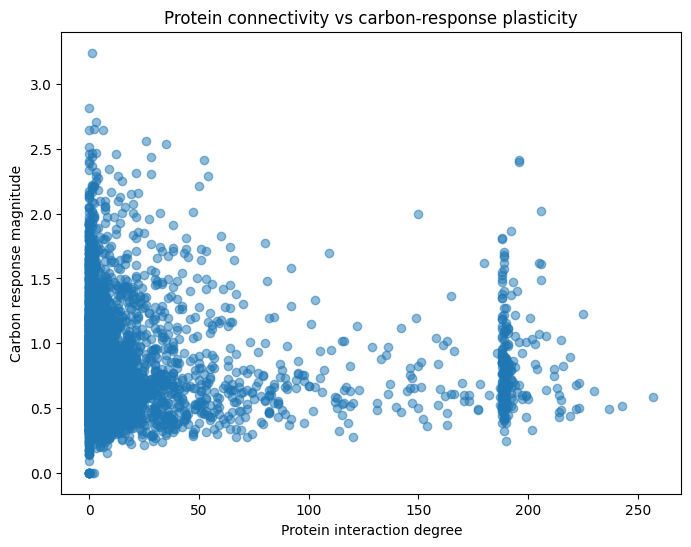

In [106]:
plt.figure(figsize=(8, 6))

plt.scatter(
    gene_response["degree"],
    gene_response["carbon_magnitude"],
    alpha=0.5
)

plt.xlabel("Protein interaction degree")
plt.ylabel("Carbon response magnitude")
plt.title("Protein connectivity vs carbon-response plasticity")

plt.show()

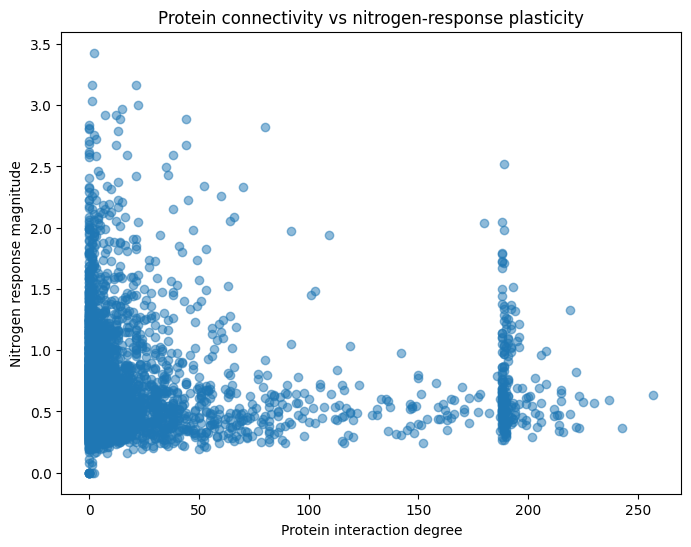

In [107]:
plt.figure(figsize=(8, 6))

plt.scatter(
    gene_response["degree"],
    gene_response["nitrogen_magnitude"],
    alpha=0.5
)

plt.xlabel("Protein interaction degree")
plt.ylabel("Nitrogen response magnitude")
plt.title("Protein connectivity vs nitrogen-response plasticity")

plt.show()

In [108]:
list(G.neighbors("b0002"))

['b0436',
 'b0473',
 'b1945',
 'b2926',
 'b3347',
 'b3823',
 'b3940',
 'b4024',
 'b4052',
 'b4142',
 'b4207']

In [109]:
G.degree("b0002")

11

In [110]:
gene_info = pd.read_csv(
    "precise_mg1655_all/precise_mg1655-gene_info.csv"
)

gene_info.columns.tolist()

['gene_id',
 'gene_name',
 'gene_product',
 'start',
 'end',
 'strand',
 'uniprot_id',
 'cog',
 'string_id',
 'gene_synonyms']

In [111]:
gene_info.head()

,gene_id,gene_name,gene_product,start,end,strand,uniprot_id,cog,string_id,gene_synonyms
0,b0001,thrL,thr operon leader peptide,190,255,+,P0AD86,No COG annotation,511145.b0001,NaN
1,b0002,thrA,fused aspartate kinase\/homoserine dehydrogena...,337,2799,+,P00561,Amino acid transport and metabolism,511145.b0002,NaN
2,b0003,thrB,homoserine kinase,2801,3733,+,P00547,Nucleotide transport and metabolism,511145.b0003,NaN
3,b0004,thrC,threonine synthase,3734,5020,+,P00934,Amino acid transport and metabolism,511145.b0004,NaN
4,b0005,yaaX,DUF2502 domain-containing protein YaaX,5234,5530,+,P75616,Function unknown,511145.b0005,NaN


In [112]:
gene_to_cog = (
    gene_info
    .set_index("gene_id")["cog"]
)

In [114]:
gene_to_cog = gene_to_cog.replace(
    ["No COG annotation", "Function unknown"],
    np.nan
)

In [115]:
gene = "b0002"

partners = list(G.neighbors(gene))

partner_roles = gene_to_cog.reindex(partners)

partner_roles

gene_id
b0436    Cell cycle control, cell division, chromosome ...
b0473    Post-translational modification, protein turno...
b1945                                        Cell motility
b2926                  Nucleotide transport and metabolism
b3347    Post-translational modification, protein turno...
b3823                  Amino acid transport and metabolism
b3940                  Amino acid transport and metabolism
b4024                  Amino acid transport and metabolism
b4052                Replication, recombination and repair
b4142    Post-translational modification, protein turno...
b4207    Post-translational modification, protein turno...
Name: cog, dtype: object

In [121]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from scipy.stats import entropy, spearmanr

In [122]:
def partner_role_metrics(gene, G, gene_to_cog):

    partners = list(G.neighbors(gene))

    roles = gene_to_cog.reindex(partners).dropna()

    n_annotated = len(roles)

    if n_annotated == 0:
        return np.nan, np.nan, np.nan, 0

    counts = roles.value_counts()

    # number of different roles
    richness = len(counts)

    # Shannon entropy
    shannon = entropy(counts.values)

    # normalized Shannon entropy
    if richness > 1:
        normalized_shannon = shannon / np.log(richness)
    else:
        normalized_shannon = 0

    return (
        richness,
        shannon,
        normalized_shannon,
        n_annotated
    )

In [123]:
def partner_coordination(gene, G, expression_matrix):

    partners = [
        p for p in G.neighbors(gene)
        if p in expression_matrix.columns
    ]

    if len(partners) < 2:
        return np.nan, np.nan, len(partners)

    partner_expr = expression_matrix[partners]

    corr = partner_expr.corr(method="pearson")

    # upper triangle, excluding diagonal
    mask = np.triu(
        np.ones(corr.shape, dtype=bool),
        k=1
    )

    values = corr.values[mask]

    values = values[~np.isnan(values)]

    if len(values) == 0:
        return np.nan, np.nan, len(partners)

    mean_signed = np.mean(values)
    mean_absolute = np.mean(np.abs(values))

    return (
        mean_signed,
        mean_absolute,
        len(partners)
    )

In [124]:
results = []

for gene in G.nodes():

    degree = G.degree(gene)

    # functional diversity
    (
        role_richness,
        role_diversity,
        normalized_role_diversity,
        n_annotated_partners
    ) = partner_role_metrics(
        gene,
        G,
        gene_to_cog
    )

    # carbon expression coordination
    (
        carbon_coord,
        carbon_abs_coord,
        n_carbon_partners
    ) = partner_coordination(
        gene,
        G,
        carbon_condition_mean
    )

    # nitrogen expression coordination
    (
        nitrogen_coord,
        nitrogen_abs_coord,
        n_nitrogen_partners
    ) = partner_coordination(
        gene,
        G,
        nitrogen_condition_mean
    )

    results.append({
        "gene_id": gene,

        "degree": degree,

        "role_richness": role_richness,
        "role_diversity": role_diversity,
        "normalized_role_diversity": normalized_role_diversity,
        "n_annotated_partners": n_annotated_partners,

        "carbon_coordination": carbon_coord,
        "carbon_abs_coordination": carbon_abs_coord,
        "n_carbon_partners": n_carbon_partners,

        "nitrogen_coordination": nitrogen_coord,
        "nitrogen_abs_coordination": nitrogen_abs_coord,
        "n_nitrogen_partners": n_nitrogen_partners
    })


network_analysis = pd.DataFrame(results)

In [125]:
network_analysis.head()

,gene_id,degree,role_richness,role_diversity,normalized_role_diversity,n_annotated_partners,carbon_coordination,carbon_abs_coordination,n_carbon_partners,nitrogen_coordination,nitrogen_abs_coordination,n_nitrogen_partners
0,b0002,11,6.0,1.594167,0.889721,11,0.222952,0.331832,11,0.069781,0.252333,11
1,b0436,112,14.0,1.714710,0.649743,110,0.203410,0.367841,112,0.176285,0.376362,112
2,b0473,119,17.0,2.219585,0.783416,107,0.129379,0.381537,119,0.078973,0.354400,119
3,b1945,109,15.0,2.388152,0.881871,106,0.147431,0.323996,109,0.102791,0.368962,109
4,b2926,78,9.0,1.622029,0.738217,77,0.267668,0.399792,78,0.173468,0.359361,78


In [126]:
analysis_df = network_analysis[
    (network_analysis["degree"] >= 3) &
    (network_analysis["n_annotated_partners"] >= 3) &
    (network_analysis["n_carbon_partners"] >= 3) &
    (network_analysis["n_nitrogen_partners"] >= 3)
].copy()

print(network_analysis.shape)
print(analysis_df.shape)

(3173, 12)
(2323, 12)


In [127]:
tmp = analysis_df.dropna(
    subset=["degree", "normalized_role_diversity"]
)

rho_degree_role, p_degree_role = spearmanr(
    tmp["degree"],
    tmp["normalized_role_diversity"]
)

print("Degree vs functional role diversity")
print("Spearman rho =", rho_degree_role)
print("p-value =", p_degree_role)

Degree vs functional role diversity
Spearman rho = -0.5411004404093734
p-value = 7.699470125573866e-177


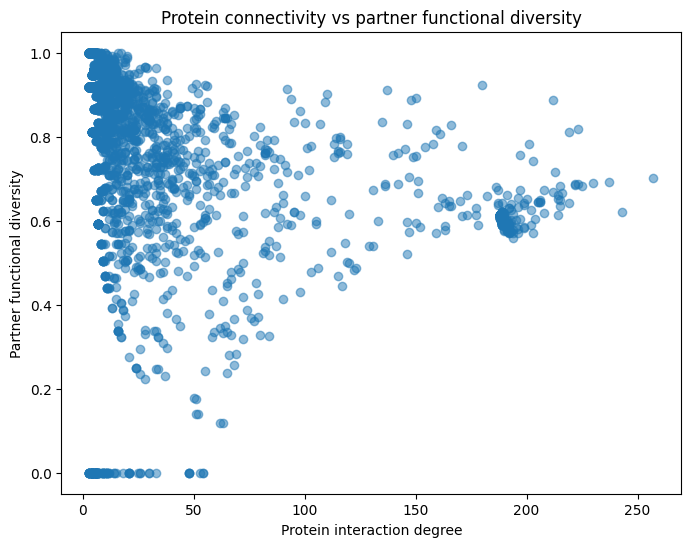

In [128]:
plt.figure(figsize=(8, 6))

plt.scatter(
    tmp["degree"],
    tmp["normalized_role_diversity"],
    alpha=0.5
)

plt.xlabel("Protein interaction degree")
plt.ylabel("Partner functional diversity")
plt.title("Protein connectivity vs partner functional diversity")

plt.show()

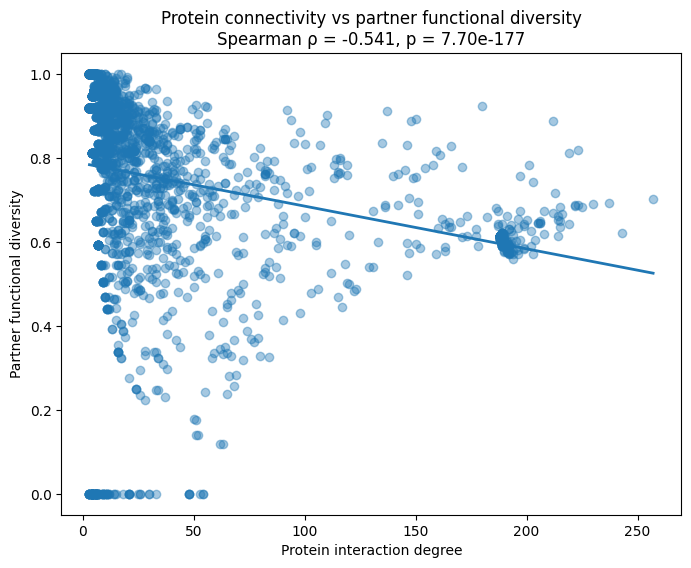

In [143]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    tmp["degree"],
    tmp["normalized_role_diversity"],
    alpha=0.4
)

# linear trend line
x = tmp["degree"].values
y = tmp["normalized_role_diversity"].values

coef = np.polyfit(x, y, 1)
trend = np.poly1d(coef)

x_line = np.linspace(x.min(), x.max(), 200)

plt.plot(
    x_line,
    trend(x_line),
    linewidth=2
)

plt.xlabel("Protein interaction degree")
plt.ylabel("Partner functional diversity")

plt.title(
    f"Protein connectivity vs partner functional diversity\n"
    f"Spearman ρ = {rho_degree_role:.3f}, "
    f"p = {p_degree_role:.2e}"
)

plt.show()

In [144]:
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

In [149]:
tmp_c = analysis_df.dropna(
    subset=[
        "normalized_role_diversity",
        "carbon_coordination"
    ]
)

rho_role_carbon, p_role_carbon = spearmanr(
    tmp_c["normalized_role_diversity"],
    tmp_c["carbon_coordination"]
)

print("Functional diversity vs carbon coordination")
print("rho =", rho_role_carbon)
print("p =", p_role_carbon)

Functional diversity vs carbon coordination
rho = -0.08149249394084791
p = 8.418508506347343e-05


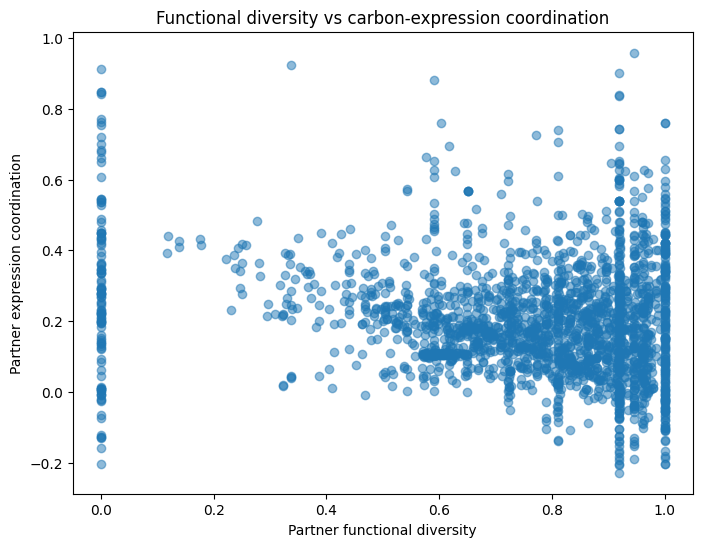

In [150]:
plt.figure(figsize=(8, 6))

plt.scatter(
    tmp_c["normalized_role_diversity"],
    tmp_c["carbon_coordination"],
    alpha=0.5
)

plt.xlabel("Partner functional diversity")
plt.ylabel("Partner expression coordination")
plt.title(
    "Functional diversity vs carbon-expression coordination"
)

plt.show()

In [131]:
tmp_n = analysis_df.dropna(
    subset=[
        "normalized_role_diversity",
        "nitrogen_coordination"
    ]
)

rho_role_nitrogen, p_role_nitrogen = spearmanr(
    tmp_n["normalized_role_diversity"],
    tmp_n["nitrogen_coordination"]
)

print("Functional diversity vs nitrogen coordination")
print("rho =", rho_role_nitrogen)
print("p =", p_role_nitrogen)

Functional diversity vs nitrogen coordination
rho = -0.15434489822052136
p = 7.438018669978919e-14


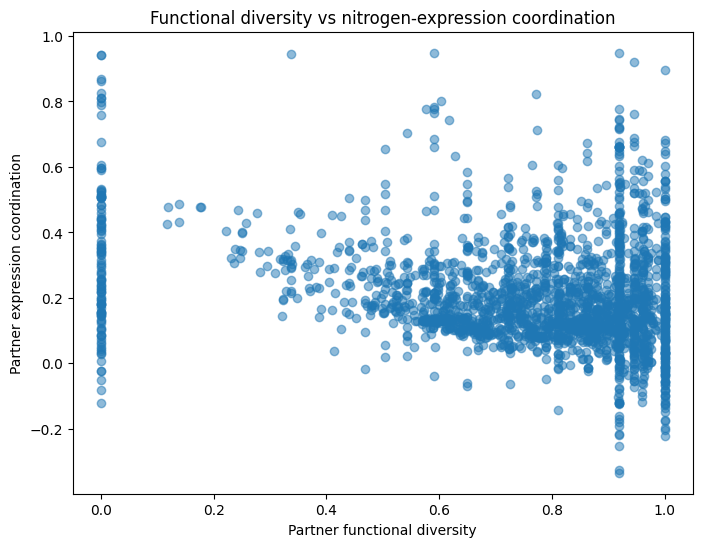

In [132]:
plt.figure(figsize=(8, 6))

plt.scatter(
    tmp_n["normalized_role_diversity"],
    tmp_n["nitrogen_coordination"],
    alpha=0.5
)

plt.xlabel("Partner functional diversity")
plt.ylabel("Partner expression coordination")
plt.title(
    "Functional diversity vs nitrogen-expression coordination"
)

plt.show()

In [133]:
tmp_c = analysis_df.dropna(
    subset=["degree", "carbon_coordination"]
)

rho_degree_carbon, p_degree_carbon = spearmanr(
    tmp_c["degree"],
    tmp_c["carbon_coordination"]
)

print("Degree vs carbon coordination")
print("rho =", rho_degree_carbon)
print("p =", p_degree_carbon)

Degree vs carbon coordination
rho = -0.08006137236443119
p = 0.0001120562926813023


In [134]:
tmp_n = analysis_df.dropna(
    subset=["degree", "nitrogen_coordination"]
)

rho_degree_nitrogen, p_degree_nitrogen = spearmanr(
    tmp_n["degree"],
    tmp_n["nitrogen_coordination"]
)

print("Degree vs nitrogen coordination")
print("rho =", rho_degree_nitrogen)
print("p =", p_degree_nitrogen)

Degree vs nitrogen coordination
rho = -0.11619674474286866
p = 1.9496218420475653e-08


In [135]:
def within_between_coordination(
    gene,
    G,
    expression_matrix,
    gene_to_cog
):

    partners = [
        p for p in G.neighbors(gene)
        if (
            p in expression_matrix.columns
            and p in gene_to_cog.index
            and pd.notna(gene_to_cog.get(p))
        )
    ]

    if len(partners) < 2:
        return np.nan, np.nan, 0, 0

    corr = expression_matrix[partners].corr()

    within = []
    between = []

    for i in range(len(partners)):
        for j in range(i + 1, len(partners)):

            p1 = partners[i]
            p2 = partners[j]

            r = corr.loc[p1, p2]

            if pd.isna(r):
                continue

            role1 = gene_to_cog[p1]
            role2 = gene_to_cog[p2]

            if role1 == role2:
                within.append(r)
            else:
                between.append(r)

    mean_within = (
        np.mean(within)
        if len(within) > 0
        else np.nan
    )

    mean_between = (
        np.mean(between)
        if len(between) > 0
        else np.nan
    )

    return (
        mean_within,
        mean_between,
        len(within),
        len(between)
    )

In [136]:
within_between_results = []

for gene in G.nodes():

    (
        carbon_within,
        carbon_between,
        n_carbon_within,
        n_carbon_between
    ) = within_between_coordination(
        gene,
        G,
        carbon_condition_mean,
        gene_to_cog
    )

    (
        nitrogen_within,
        nitrogen_between,
        n_nitrogen_within,
        n_nitrogen_between
    ) = within_between_coordination(
        gene,
        G,
        nitrogen_condition_mean,
        gene_to_cog
    )

    within_between_results.append({
        "gene_id": gene,

        "carbon_within": carbon_within,
        "carbon_between": carbon_between,
        "n_carbon_within_pairs": n_carbon_within,
        "n_carbon_between_pairs": n_carbon_between,

        "nitrogen_within": nitrogen_within,
        "nitrogen_between": nitrogen_between,
        "n_nitrogen_within_pairs": n_nitrogen_within,
        "n_nitrogen_between_pairs": n_nitrogen_between
    })


within_between_df = pd.DataFrame(
    within_between_results
)

In [137]:
network_analysis = network_analysis.merge(
    within_between_df,
    on="gene_id",
    how="left"
)

In [138]:
network_analysis["carbon_within_minus_between"] = (
    network_analysis["carbon_within"]
    -
    network_analysis["carbon_between"]
)

network_analysis["nitrogen_within_minus_between"] = (
    network_analysis["nitrogen_within"]
    -
    network_analysis["nitrogen_between"]
)

In [139]:
network_analysis[
    [
        "gene_id",
        "degree",
        "carbon_within",
        "carbon_between",
        "carbon_within_minus_between"
    ]
].dropna().head(20)

,gene_id,degree,carbon_within,carbon_between,carbon_within_minus_between
0,b0002,11,0.158398,0.235583,-0.077184
1,b0436,112,0.404717,0.118509,0.286209
2,b0473,119,0.338870,0.143776,0.195094
3,b1945,109,0.478164,0.108621,0.369543
4,b2926,78,0.425512,0.230447,0.195064
5,b3347,82,0.384182,0.147992,0.236190
7,b3940,8,0.286686,0.298099,-0.011413
8,b4024,5,0.350215,0.263557,0.086657
9,b4052,40,0.257255,0.114815,0.142440
10,b4142,36,0.123100,0.093332,0.029768


In [140]:
from scipy.stats import wilcoxon

In [141]:
carbon_test = network_analysis.dropna(
    subset=[
        "carbon_within",
        "carbon_between"
    ]
)

stat, p = wilcoxon(
    carbon_test["carbon_within"],
    carbon_test["carbon_between"]
)

print("Carbon:")
print(
    "Mean within =",
    carbon_test["carbon_within"].mean()
)
print(
    "Mean between =",
    carbon_test["carbon_between"].mean()
)
print("Wilcoxon p =", p)

Carbon:
Mean within = 0.29433175885956947
Mean between = 0.15788837808006853
Wilcoxon p = 7.870125158171017e-147


In [142]:
nitrogen_test = network_analysis.dropna(
    subset=[
        "nitrogen_within",
        "nitrogen_between"
    ]
)

stat, p = wilcoxon(
    nitrogen_test["nitrogen_within"],
    nitrogen_test["nitrogen_between"]
)

print("Nitrogen:")
print(
    "Mean within =",
    nitrogen_test["nitrogen_within"].mean()
)
print(
    "Mean between =",
    nitrogen_test["nitrogen_between"].mean()
)
print("Wilcoxon p =", p)

Nitrogen:
Mean within = 0.3092315181035943
Mean between = 0.1454364525693964
Wilcoxon p = 2.1155086239321992e-152


# role diversity vs. expression coordination

In [151]:
tmp_c = network_analysis.dropna(
    subset=[
        "normalized_role_diversity",
        "carbon_coordination"
    ]
).copy()

rho_c, p_c = spearmanr(
    tmp_c["normalized_role_diversity"],
    tmp_c["carbon_coordination"]
)

print("Role diversity vs carbon coordination")
print("rho =", rho_c)
print("p =", p_c)

Role diversity vs carbon coordination
rho = -0.07270450328795669
p = 0.00015658222067003539


In [152]:
tmp_n = network_analysis.dropna(
    subset=[
        "normalized_role_diversity",
        "nitrogen_coordination"
    ]
).copy()

rho_n, p_n = spearmanr(
    tmp_n["normalized_role_diversity"],
    tmp_n["nitrogen_coordination"]
)

print("Role diversity vs nitrogen coordination")
print("rho =", rho_n)
print("p =", p_n)

Role diversity vs nitrogen coordination
rho = -0.13256627161595158
p = 4.697954078680019e-12


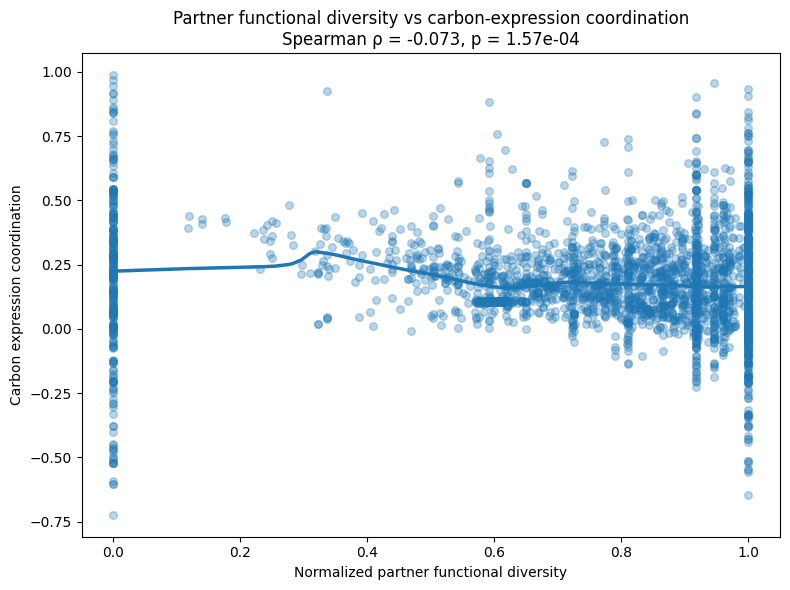

In [153]:
from statsmodels.nonparametric.smoothers_lowess import lowess

x = tmp_c["normalized_role_diversity"].values
y = tmp_c["carbon_coordination"].values

smooth = lowess(
    endog=y,
    exog=x,
    frac=0.3,
    return_sorted=True
)

plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    alpha=0.3,
    s=30
)

plt.plot(
    smooth[:, 0],
    smooth[:, 1],
    linewidth=2.5
)

plt.xlabel("Normalized partner functional diversity")
plt.ylabel("Carbon expression coordination")

plt.title(
    "Partner functional diversity vs carbon-expression coordination\n"
    f"Spearman ρ = {rho_c:.3f}, p = {p_c:.2e}"
)

plt.tight_layout()
plt.show()

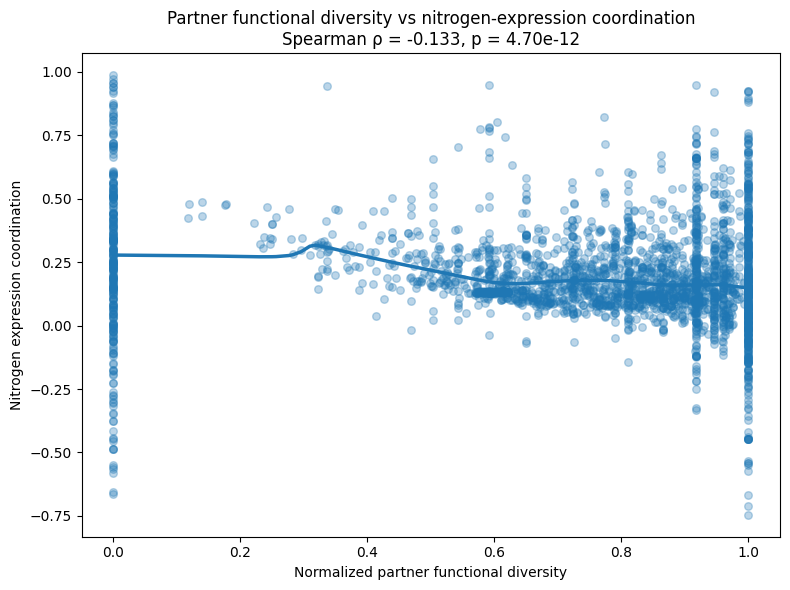

In [154]:
x = tmp_n["normalized_role_diversity"].values
y = tmp_n["nitrogen_coordination"].values

smooth = lowess(
    endog=y,
    exog=x,
    frac=0.3,
    return_sorted=True
)

plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    alpha=0.3,
    s=30
)

plt.plot(
    smooth[:, 0],
    smooth[:, 1],
    linewidth=2.5
)

plt.xlabel("Normalized partner functional diversity")
plt.ylabel("Nitrogen expression coordination")

plt.title(
    "Partner functional diversity vs nitrogen-expression coordination\n"
    f"Spearman ρ = {rho_n:.3f}, p = {p_n:.2e}"
)

plt.tight_layout()
plt.show()

In [155]:
import statsmodels.api as sm

model_df = network_analysis.dropna(
    subset=[
        "degree",
        "normalized_role_diversity",
        "carbon_coordination"
    ]
).copy()

X_model = model_df[
    ["degree", "normalized_role_diversity"]
]

X_model = sm.add_constant(X_model)

model = sm.OLS(
    model_df["carbon_coordination"],
    X_model
).fit()

print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     carbon_coordination   R-squared:                       0.013
Model:                             OLS   Adj. R-squared:                  0.012
Method:                  Least Squares   F-statistic:                     17.68
Date:                 Sun, 04 Oct 2026   Prob (F-statistic):           2.35e-08
Time:                         15:13:47   Log-Likelihood:                 582.79
No. Observations:                 2699   AIC:                            -1160.
Df Residuals:                     2696   BIC:                            -1142.
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const       

In [156]:
model_df = network_analysis.dropna(
    subset=[
        "degree",
        "normalized_role_diversity",
        "nitrogen_coordination"
    ]
).copy()

X_model = model_df[
    ["degree", "normalized_role_diversity"]
]

X_model = sm.add_constant(X_model)

model_n = sm.OLS(
    model_df["nitrogen_coordination"],
    X_model
).fit()

print(model_n.summary())

                              OLS Regression Results                             
Dep. Variable:     nitrogen_coordination   R-squared:                       0.038
Model:                               OLS   Adj. R-squared:                  0.038
Method:                    Least Squares   F-statistic:                     53.89
Date:                   Sun, 04 Oct 2026   Prob (F-statistic):           1.13e-23
Time:                           15:14:46   Log-Likelihood:                 549.78
No. Observations:                   2699   AIC:                            -1094.
Df Residuals:                       2696   BIC:                            -1076.
Df Model:                              2                                         
Covariance Type:               nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------